In [44]:
import torch
print(torch.__version__)            # should now end in +cu126
print(torch.version.cuda)           # should print 12.6
print(torch.cuda.is_available())    # should be True
print(torch.cuda.get_device_name(0))  # should show RTX 3050
import sys; print(sys.executable)

2.8.0+cu126
12.6
True
NVIDIA GeForce RTX 3050 Laptop GPU
c:\Users\wtpir\Documents\Pytorch\venv\Scripts\python.exe


In [45]:
import os 
import tarfile 
import matplotlib.pyplot as plt
import numpy as np
import requests
import scipy
from PIL import Image
from torch.utils.data import DataLoader , Subset , random_split , Dataset

from torchvision import transforms
from tqdm.auto import tqdm
import helper_utils                                    # custom/local helper functions

In [46]:
def download_dataset():
    
    data_dir = "flower_data"
    
    image_folder_path = os.path.join(data_dir , "jpg")
    labels_file_path = os.path.join(data_dir , "imagelabels.mat")
    tgz_path = os.path.join(data_dir , "102flowers.tgz")
    
    if os.path.exists(image_folder_path) and os.path.exists(labels_file_path):
        print("Dataset is already downloaded")
        return
    
    print("dataset not found locally . downloading ....")
    
    image_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
    labels_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat"
    
    os.makedirs(data_dir , exist_ok=True)
    print("Downloading images....")
    
    response = requests.get(image_url , stream=True)
    total_size = int(response.headers.get("content-length",0))
    
    with open(tgz_path , "wb") as file :
        for data in tqdm(
            response.iter_content(chunk_size=1024),
            total = total_size // 1024,
        ):
            file.write(data)
        print("Extracting files...")

    with tarfile.open(tgz_path, "r:gz") as tar:
        tar.extractall(data_dir)
        
    print("Downloading labels ....")
    
    response = requests.get(labels_url)
    
    with open(labels_file_path , "wb") as file :
        file.write(response.content)
        
    print(f"Dataset downloaded and extracted to '{data_dir}'.")

    # create labels_description.txt
    labels_description = [
        'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily',
        'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon', "colt's foot", 'king protea',
        'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower',
        'giant white arum lily', 'fire lily', 'pincushion flower', 'fritillary', 'red ginger', 'grape hyacinth',
        'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke', 'sweet william', 'carnation',
        'garden phlox', 'love in the mist', 'mexican aster', 'alpine sea holly', 'ruby-lipped cattleya', 'cape flower',
        'great masterwort', 'siam tulip', 'lenten rose', 'barbeton daisy', 'daffodil', 'sword lily', 'poinsettia',
        'bolero deep blue', 'wallflower', 'marigold', 'buttercup', 'oxeye daisy', 'common dandelion', 'petunia',
        'wild pansy', 'primula', 'sunflower', 'pelargonium', 'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia',
        'pink-yellow dahlia?', 'cautleya spicata', 'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy',
        'osteospermum', 'spring crocus', 'bearded iris', 'windflower', 'tree poppy', 'gazania', 'azalea', 'water lily',
        'rose', 'thorn apple', 'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani',
        'clematis', 'hibiscus', 'columbine', 'desert-rose', 'tree mallow', 'magnolia', 'cyclamen ', 'watercress',
        'canna lily', 'hippeastrum ', 'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia', 'mallow',
        'mexican petunia', 'bromelia', 'blanket flower', 'trumpet creeper', 'blackberry lily'
    ]

    with open(os.path.join(data_dir, "labels_description.txt"), "w") as f:
        for idx, label in enumerate(labels_description, start=1):
            f.write(f"{label}\n")

In [47]:
download_dataset()

Dataset is already downloaded


In [48]:
path_dataset= "./flower_data"
helper_utils.print_data_folder_structure(path_dataset, max_depth=1)

flower_data/
├── 102flowers.tgz
├── imagelabels.mat
├── jpg/
└── labels_description.txt


In [49]:
class RobustFlowerDataset(Dataset):
    
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.img_dir = os.path.join(root_dir, "jpg")
        self.transform = transform
        self.labels = self.load_and_correct_labels()
        self.error_logs = []

    def __getitem__(self, idx):
        for attempt in range(len(self)):
            try:
                image = self.retrieve_image(idx)
                if self.transform:
                    image = self.transform(image)
                label = int(self.labels[idx])
                return image, label
            except Exception as e:
                self.log_error(idx, e)
                idx = (idx + 1) % len(self)

        raise RuntimeError(f"Could not load a valid sample for index {idx}.")

    def __len__(self):
        return len(self.labels)

    def retrieve_image(self, idx):
        img_name = f"image_{idx+1:05d}.jpg"
        img_path = os.path.join(self.img_dir, img_name)

        with Image.open(img_path) as img:
            img.verify()

        image = Image.open(img_path)
        image.load()

        if image.size[0] < 32 or image.size[1] < 32:
            raise ValueError(f"Image too small: {image.size}")

        if image.mode != "RGB":
            image = image.convert("RGB")

        return image

    def load_and_correct_labels(self):
        self.labels_mat = scipy.io.loadmat(
            os.path.join(self.root_dir, "imagelabels.mat")
        )

        labels = self.labels_mat["labels"][0] - 1
        return labels

    def log_error(self, idx, e):
        img_name = f"image_{idx + 1:05d}.jpg"
        img_path = os.path.join(self.img_dir, img_name)
        self.error_logs.append(
            {
                "index": idx,
                "error": str(e),
                "path": img_path,
            }
        )
        print(f"Warning: Skipping corrupted image {idx}: {e}")

    def get_error_summary(self):
        if not self.error_logs:
            print("No errors encountered - dataset is clean!")
        else:
            print(f"\nEncountered {len(self.error_logs)} problematic images:")
            for error in self.error_logs[:5]:
                print(f"  Index {error['index']}: {error['error']}")
            if len(self.error_logs) > 5:
                print(f"  ... and {len(self.error_logs) - 5} more")


In [50]:

corrupted_dataset_path = os.path.join('.', 'corrupted_flower_data')

if not os.path.exists(corrupted_dataset_path):
    import shutil
    shutil.copytree('./flower_data', corrupted_dataset_path)

  
    for img_idx in [1, 3, 5]:  
        img_path = os.path.join(corrupted_dataset_path, 'jpg', f'image_{img_idx:05d}.jpg')
        if not os.path.exists(img_path):
            continue

        if img_idx in (1, 5):

            Image.new('RGB', (8, 8), color='red').save(img_path)
        elif img_idx == 3:
            Image.new('L', (64, 64), color=128).save(img_path)

robust_dataset = RobustFlowerDataset(corrupted_dataset_path)

In [51]:
# Define the mean values for normalization.
mean = [0.485, 0.456, 0.406]
# Define the standard deviation values for normalization.
std = [0.229, 0.224, 0.225]

In [ ]:
def get_augmentation_transform(mean, std):
    return transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(20),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
        transforms.RandomErasing(p=0.25),
    ])

In [53]:
def get_eval_transform(mean, std):
    return transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

In [54]:
import torch 
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision

In [55]:
train_dataset_full = RobustFlowerDataset(
    corrupted_dataset_path,
    transform=get_augmentation_transform(mean=mean, std=std)
)
eval_dataset_full = RobustFlowerDataset(
    corrupted_dataset_path,
    transform=get_eval_transform(mean=mean, std=std)
)

total_size = len(train_dataset_full)
val_size = int(0.15 * total_size)
test_size = int(0.15 * total_size)
train_size = total_size - val_size - test_size

generator = torch.Generator().manual_seed(42)
train_indices, val_indices, test_indices = random_split(
    range(total_size), [train_size, val_size, test_size], generator=generator
)

train_dataset = Subset(train_dataset_full, train_indices.indices)
val_dataset = Subset(eval_dataset_full, val_indices.indices)
test_dataset = Subset(eval_dataset_full, test_indices.indices)

In [56]:
print(f"Length of training dataset:   {len(train_dataset)}")
print(f"Length of validation dataset: {len(val_dataset)}")
print(f"Length of test dataset:       {len(test_dataset)}")

Length of training dataset:   5733
Length of validation dataset: 1228
Length of test dataset:       1228


In [57]:
def conv_block(in_c, out_c):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            conv_block(3, 32),     # 224 -> 112
            conv_block(32, 64),    # 112 -> 56
            conv_block(64, 128),   # 56 -> 28
            conv_block(128, 256),  # 28 -> 14
            conv_block(256, 256),  # 14 -> 7
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 102),
        )

    def forward(self, x):
        return self.layers(x)

In [58]:
model = SimpleModel()
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss() 

In [59]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("cuda")
else :
    device = torch.device("cpu")
    print("cpu")

cuda


In [60]:
def train_epoch(model, loss_function, optimizer, scheduler, scaler, train_loader, device):
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0
    total_batches = len(train_loader)
    use_amp = device.type == "cuda"

    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs = model(inputs)
            loss = loss_function(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        epoch_loss += loss.item()
        correct += outputs.argmax(1).eq(targets).sum().item()
        total += targets.size(0)

        if (batch_idx + 1) % 30 == 0 or (batch_idx + 1) == total_batches:
            print(f"\tStep {batch_idx + 1}/{total_batches} - Loss: {epoch_loss / (batch_idx + 1):.3f}")

    return epoch_loss / total_batches, correct / total * 100

In [61]:
def evaluate(model, data_loader, device):
    model = model.to(device)
    model.eval()
    num_correct_predictions = 0
    total_predictions = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted_indices = outputs.max(1)
            correct_predictions = predicted_indices.eq(targets)
            num_correct_predictions += correct_predictions.sum().item()
            total_predictions += targets.size(0)

    accuracy_percentage = (num_correct_predictions / total_predictions) * 100
    print(f"\tAccuracy - {accuracy_percentage:.2f}%")
    return accuracy_percentage


In [62]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True,
                          num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [63]:
num_epochs = 50

model = SimpleModel().to(device)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-3,
    steps_per_epoch=len(train_loader), epochs=num_epochs
)
loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

train_loss, train_acc, val_acc = [], [], []
best_val = 0.0

for epoch in range(num_epochs):
    print(f"\n[Training] Epoch {epoch+1}/{num_epochs}:")
    loss, t_acc = train_epoch(model, loss_function, optimizer, scheduler, scaler, train_loader, device)
    train_loss.append(loss)
    train_acc.append(t_acc)
    print(f"\tTrain Accuracy: {t_acc:.2f}%")

    print(f"[Validation] Epoch {epoch+1}:")
    v_acc = evaluate(model, val_loader, device)
    val_acc.append(v_acc)

    if v_acc > best_val:
        best_val = v_acc
        torch.save(model.state_dict(), "best_model.pt")


[Training] Epoch 1/50:


	Step 30/359 - Loss: 4.632
	Step 60/359 - Loss: 4.539
	Step 90/359 - Loss: 4.481
	Step 120/359 - Loss: 4.441
	Step 150/359 - Loss: 4.406
	Step 180/359 - Loss: 4.376
	Step 210/359 - Loss: 4.342
	Step 240/359 - Loss: 4.308
	Step 270/359 - Loss: 4.283
	Step 300/359 - Loss: 4.258
	Step 330/359 - Loss: 4.234
	Step 359/359 - Loss: 4.210
	Train Accuracy: 8.79%
[Validation] Epoch 1:
	Accuracy - 13.36%

[Training] Epoch 2/50:
	Step 30/359 - Loss: 3.989
	Step 60/359 - Loss: 3.945
	Step 90/359 - Loss: 3.944
	Step 120/359 - Loss: 3.938
	Step 150/359 - Loss: 3.929
	Step 180/359 - Loss: 3.917
	Step 210/359 - Loss: 3.908
	Step 240/359 - Loss: 3.900
	Step 270/359 - Loss: 3.892
	Step 300/359 - Loss: 3.889
	Step 330/359 - Loss: 3.886
	Step 359/359 - Loss: 3.883
	Train Accuracy: 13.33%
[Validation] Epoch 2:
	Accuracy - 19.22%

[Training] Epoch 3/50:
	Step 30/359 - Loss: 3.809
	Step 60/359 - Loss: 3.786
	Step 90/359 - Loss: 3.803
	Step 120/359 - Loss: 3.816
	Step 150/359 - Loss: 3.809
	Step 180/359 - Loss

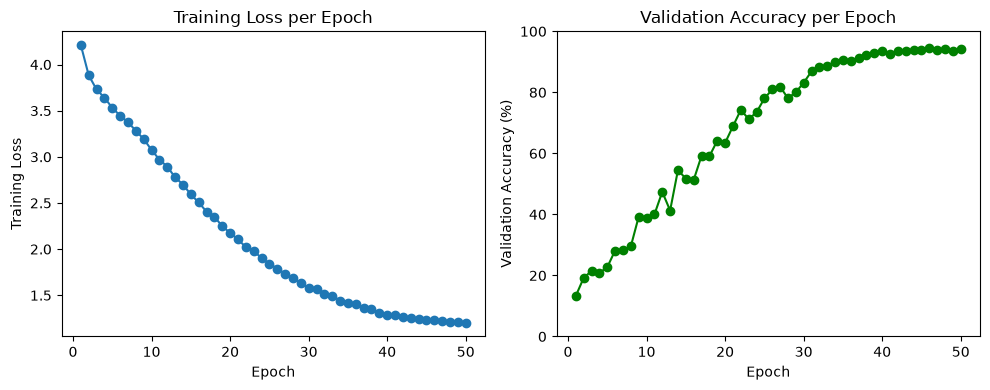

In [64]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(train_loss) + 1), train_loss, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss per Epoch")

plt.subplot(1, 2, 2)
plt.plot(range(1, len(val_acc) + 1), val_acc, marker='o', color='green')
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy per Epoch")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [66]:
model.load_state_dict(torch.load("best_model.pt"))
print("\n[Final Test Evaluation]")
test_accuracy = evaluate(model, test_loader, device)


[Final Test Evaluation]
	Accuracy - 93.49%
